<a href="https://colab.research.google.com/github/haikalluthfi535-droid/analisis-imdb-top-1000/blob/main/Untitled4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATASET DIABETES
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64

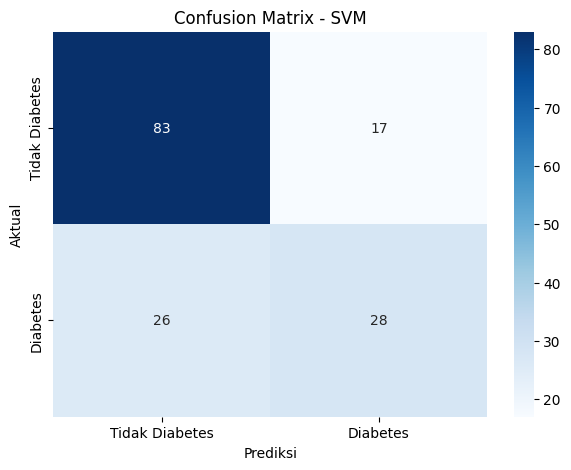

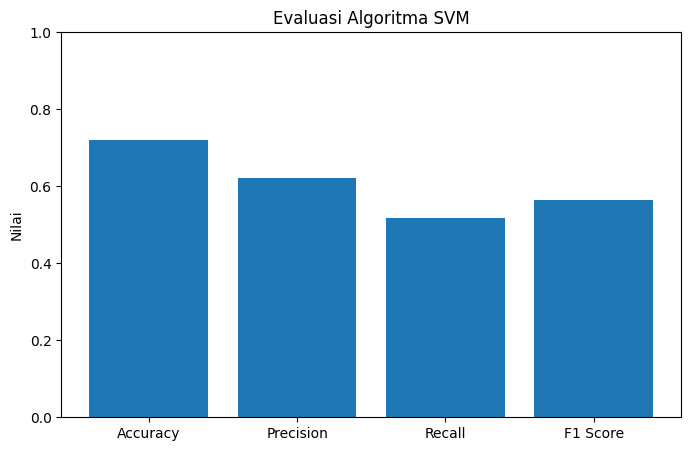


KESIMPULAN
Model SVM berhasil melakukan klasifikasi.
Accuracy : 72.08 %
Precision: 62.22 %
Recall   : 51.85 %
F1 Score : 56.57 %


In [2]:
# ==========================================
# KLASIFIKASI SVM - PIMA INDIANS DIABETES
# Nama: Luthfi Haikal R
# NIM: 241011400913
# ==========================================

# 1. Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# 2. Mengambil Dataset
url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"

df = pd.read_csv(url)

# 3. Menampilkan Dataset
print("DATASET DIABETES")
print(df.head())

print("\nInformasi Dataset:")
print(df.info())

print("\nStatistik Dataset:")
print(df.describe())

# 4. Memeriksa Data Kosong
print("\nData Kosong:")
print(df.isnull().sum())

# 5. Memisahkan Fitur dan Target
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# 6. Membagi Data Training dan Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 7. Normalisasi Data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 8. Membuat Model SVM
model = SVC(kernel="linear", C=1.0)

# 9. Training Model
model.fit(X_train, y_train)

print("\nTraining SVM Berhasil!")

# 10. Prediksi
y_pred = model.predict(X_test)

# 11. Evaluasi Model
print("\nHASIL EVALUASI MODEL")

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy  :", accuracy)
print("Precision :", precision)
print("Recall    :", recall)
print("F1 Score  :", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 12. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Tidak Diabetes", "Diabetes"],
    yticklabels=["Tidak Diabetes", "Diabetes"]
)

plt.title("Confusion Matrix - SVM")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

# 13. Grafik Hasil Evaluasi
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}

plt.figure(figsize=(8,5))
plt.bar(metrics.keys(), metrics.values())
plt.ylim(0, 1)
plt.title("Evaluasi Algoritma SVM")
plt.ylabel("Nilai")
plt.show()

# 14. Kesimpulan
print("\nKESIMPULAN")
print("Model SVM berhasil melakukan klasifikasi.")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")